# 🔍 Proyecto: Detección Dinámica de Fraude en Transacciones P2P
## Fase 1: Análisis Exploratorio de Datos (EDA) e Insights de Negocio

En este cuaderno realizaremos el análisis exploratorio de datos (EDA) sobre el benchmark de transacciones financieras **PaySim**. Para ello, es indispensable **entender las dinámicas operativas del fraude** antes de pasar al diseño de variables y al modelado de Machine Learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### 1. Configuración de Entorno e Importación Modular
Cargamos las librerías estándar para manipulación de datos y visualización estilizada. Para mantener una arquitectura limpia y reutilizable (buenas prácticas de ingeniería de software), importamos la función directamente desde nuestro script modular ubicado en `src/data_loader.py`.

In [2]:
import sys
import os

# Agregamos la ruta 'src' al path de python para importar nuestros scripts
sys.path.append(os.path.abspath(os.path.join('..')))

from src.data_loader import load_raw_data

# Cargamos el dataset completo
df = load_raw_data("../data/raw/PS_20174392719_1491204439457_log.csv")

# Visualizamos las primeras 5 filas
df.head()

Dataset cargado con éxito. Dimensiones: 6,362,620 filas y 11 columnas.


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


### 2. Auditoría de Calidad de Datos (Nulos y Duplicados)
Como parte fundamental de cualquier análisis exploratorio riguroso, y antes de pasar a las visualizaciones o a la transformación, debemos auditar el estado crudo del dataset. Esto nos permite verificar de forma empírica si existen valores faltantes (`NaN`), registros duplicados o anomalías estructurales en los tipos de datos.

In [8]:
# --- Auditoría de Calidad de Datos en el EDA ---
print("--- AUDITORÍA INICIAL DE DATOS ---")
print(f"Dimensiones totales del dataset: {df.shape[0]:,} filas y {df.shape[1]} columnas.")

# 1. Verificar valores nulos por columna
nulls = df.isnull().sum()
print(f"\nValores nulos totales: {nulls.sum()}")
if nulls.sum() > 0:
    print(nulls[nulls > 0])
else:
    print("✓ No se encontraron valores nulos (NaN).")

# 2. Verificar registros duplicados
duplicates = df.duplicated().sum()
print(f"\nFilas duplicadas: {duplicates}")

# 3. Verificar tipos de datos
print("\nTipos de datos por columna:")
print(df.dtypes)

--- AUDITORÍA INICIAL DE DATOS ---
Dimensiones totales del dataset: 6,362,620 filas y 11 columnas.

Valores nulos totales: 0
✓ No se encontraron valores nulos (NaN).

Filas duplicadas: 0

Tipos de datos por columna:
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object


> **💡 Conclusión de la Auditoría:**
> Como podemos confirmar con la ejecución del código, el dataset se encuentra estructuralmente limpio: **no existen valores nulos (`NaN`) ni registros duplicados**, y los tipos de datos numéricos y categóricos están correctamente definidos. 
> * *Implicación:* Esto descarta la necesidad de aplicar imputaciones complejas o eliminar filas duplicadas, permitiéndonos avanzar directamente hacia la fase de filtrado por canales de riesgo e ingeniería de características sin alterar la integridad de las transacciones.

### 3. Análisis del Desbalanceo de Clases (`isFraud`)
Uno de los mayores retos en la detección de fraudes financieros es la escasez extrema de casos positivos frente a millones de operaciones cotidianas. Examinemos la proporción real de transacciones fraudulentas.

Distribución de clases (%):
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


C:\Users\fegue\AppData\Local\Temp\ipykernel_26108\1903977809.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='isFraud', data=df, palette='Set2')


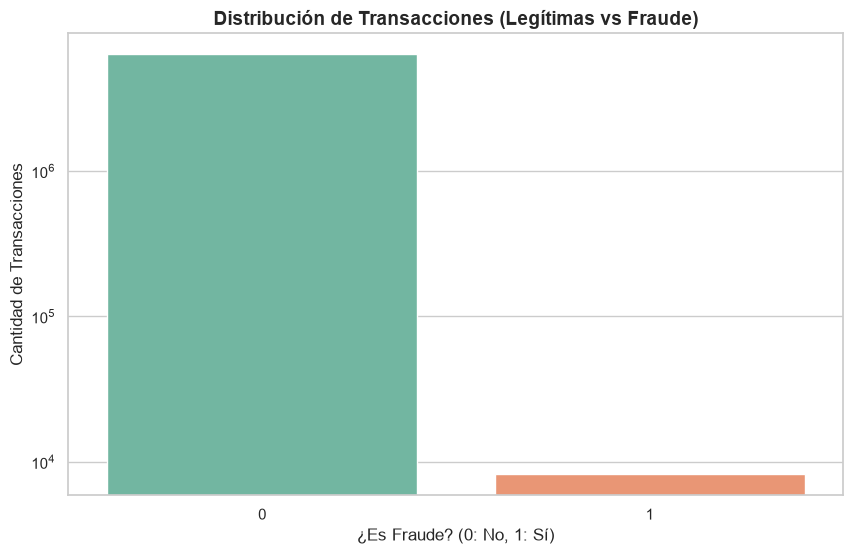

In [6]:
# Conteo y porcentaje de la variable objetivo 'isFraud'
fraud_counts = df['isFraud'].value_counts(normalize=True) * 100
print("Distribución de clases (%):")
print(fraud_counts)

# Gráfico de barras del desbalanceo
ax = sns.countplot(x='isFraud', data=df, palette='Set2')
plt.title('Distribución de Transacciones (Legítimas vs Fraude)', fontsize=14, fontweight='bold')
plt.xlabel('¿Es Fraude? (0: No, 1: Sí)')
plt.ylabel('Cantidad de Transacciones')
plt.yscale('log') # Escala logarítmica debido a la diferencia abrumadora
plt.show()

> **💡 Insight Técnico / De Negocio:**
> Como podemos evidenciar en la gráfica (visualizada en escala logarítmica debido a la diferencia abrumadora), el desbalanceo de clases es severo (**menos del 0.2% de los datos**). 
> * *Conclusión analítica:* Esto nos advierte que **nunca debemos utilizar el *Accuracy* (exactitud)** como métrica de éxito. Un modelo ingenuo que marque todo como "Legítimo" tendría un acierto del 99.8%, pero representaría pérdidas millonarias para la pasarela de pagos. Nos enfocaremos en métricas orientadas a la clase minoritaria como **PR-AUC** y **Recall**.

### 4. Distribución por Tipos de Transacción (`type`)
No todas las operaciones financieras conllevan el mismo nivel de riesgo operativo. Analicemos si el fraude se distribuye de manera uniforme o si opera bajo canales específicos.

isFraud            0         1
type                          
CASH_IN   100.000000  0.000000
CASH_OUT   99.816045  0.183955
DEBIT     100.000000  0.000000
PAYMENT   100.000000  0.000000
TRANSFER   99.231201  0.768799


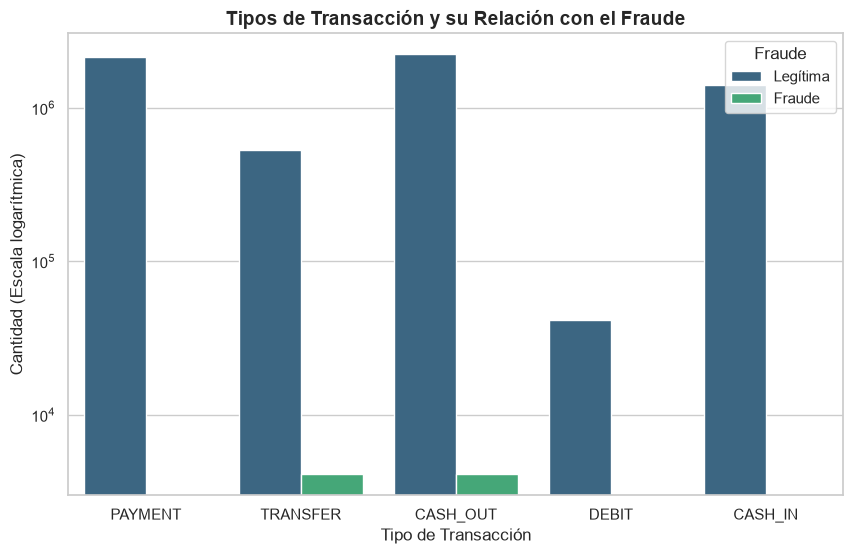

In [7]:
# Tabla cruzada entre el tipo de transacción y el fraude
fraud_by_type = pd.crosstab(df['type'], df['isFraud'], normalize='index') * 100
print(fraud_by_type)

# Visualización
sns.countplot(x='type', hue='isFraud', data=df, palette='viridis')
plt.title('Tipos de Transacción y su Relación con el Fraude', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Transacción')
plt.ylabel('Cantidad (Escala logarítmica)')
plt.yscale('log')
plt.legend(title='Fraude', labels=['Legítima', 'Fraude'])
plt.show()

> **🎯 Hallazgo Estratégico (Optimización de Modelado):**
> El análisis revela un patrón crítico e inequívoco: **el fraude en este sistema ocurre exclusivamente en las transacciones catalogadas como `TRANSFER` y `CASH_OUT`**. 
> * *Impacto para el negocio y el código:* Al avanzar en la ingeniería de características y el modelado, podremos acotar nuestro enfoque analítico exclusivamente a estas dos categorías, reduciendo el ruido computacional y optimizando la eficiencia de los algoritmos basados en árboles.